In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from ucimlrepo import fetch_ucirepo 
import matplotlib.pyplot as plt
import random
from zonolayer import fit_zonolayer, predict_zonolayer
from sklearn.model_selection import train_test_split
from SLINN import SLINN, midrad

def set_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

In [2]:
class RegressionNetwork(nn.Module):
    def __init__(self, input_dim=1, hidden_dim=6):
        super().__init__()
        self.feature_extractor = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),
        )
        self.regressor = nn.Linear(hidden_dim, 1)

    def forward(self, x, return_features=False):
        features = self.feature_extractor(x)
        out = self.regressor(features)
        
        if return_features:
            return out, features
        return out
    
class ZonoLayer(nn.Module):
    def __init__(self, hidden_dim=6, zono_dim=3):
        super().__init__()
        self.linear = nn.Linear(hidden_dim, zono_dim)

    def forward(self, features):
        return self.linear(features)
    

def train_centre(x_t, y_lb_t, y_ub_t, epochs=3000, lr=0.01, momentum=0.9, print_every=100):
    # Make sure targets are (n, 1)
    y_lb_t = y_lb_t.reshape(-1, 1)
    y_ub_t = y_ub_t.reshape(-1, 1)

    y_mid = (y_lb_t + y_ub_t) / 2

    centre_net = RegressionNetwork(input_dim=x_t.shape[1])

    # With the whole dataset in each step, SGD is full-batch gradient descent
    optimizer = torch.optim.SGD(
        centre_net.parameters(),
        lr=lr,
        momentum=momentum,
        weight_decay=0.0
    )

    criterion = nn.MSELoss()

    centre_net.train()
    for epoch in range(epochs):
        optimizer.zero_grad()

        # Forward pass on the full batch
        pred = centre_net(x_t)

        # pred and y_mid are both (n, 1)
        loss = criterion(pred, y_mid)

        loss.backward()
        optimizer.step()

        if (epoch + 1) % print_every == 0:
            print(
                f"Epoch {epoch+1}: "
                f"MSE = {loss.item():.6f}, "
                f"RMSE = {torch.sqrt(loss).item():.2f}"
            )

    return centre_net

def train_zonolayer(centre_net, x_t, y_lb_t, y_ub_t, zono_dim=3, epochs=300, lr=1e-2, print_every=50):
    for p in centre_net.parameters():
        p.requires_grad = False

    centre_net.eval()

    with torch.no_grad():
        _, features = centre_net(x_t, return_features=True)

    hidden_dim = centre_net.regressor.in_features

    # Make targets (n, 1)
    y_lb_t = y_lb_t.reshape(-1, 1)
    y_ub_t = y_ub_t.reshape(-1, 1)

    y_mid = (y_lb_t + y_ub_t) / 2

    zono_layer = ZonoLayer(
        hidden_dim=hidden_dim,
        zono_dim=zono_dim
    )

    with torch.no_grad():
        zono_layer.linear.weight[0:1, :] = (centre_net.regressor.weight.data)
        zono_layer.linear.bias[0:1] = (centre_net.regressor.bias.data)

    optimizer = torch.optim.Adam(zono_layer.parameters(), lr=lr)

    criterion = nn.MSELoss()

    for epoch in range(epochs):
        zono_layer.train()

        pred = zono_layer(features)[:, 0:1]
        loss = criterion(pred, y_mid)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if (epoch + 1) % print_every == 0:
            print(
                f"Zono epoch {epoch+1}: "
                f"MSE = {loss.item():.6f}, "
                f"RMSE = {torch.sqrt(loss).item():.2f}"
            )

    return zono_layer

In [3]:
df = pd.read_csv('Data/AmesHousing.csv')
df.head()

X = df[['Year Built']].values.astype(np.float32)

# Scale X
X_mean = X.mean()
X_std = X.std()
X = (X - X_mean) / X_std

y = df['SalePrice'].values.astype(np.float32)

Delta = np.abs(
    np.random.normal(15000, 10000, len(df))
)

b = np.random.uniform(-1, 1, size=len(df))

m = y + b * Delta

y_lower = m - Delta
y_upper = m + Delta

y_mean = y.mean()
y_std = y.std()

y_scaled = (y - y_mean) / y_std
y_lower_scaled = (y_lower - y_mean) / y_std
y_upper_scaled = (y_upper - y_mean) / y_std

X_train, X_test, \
y_train, y_test, \
y_lower_train, y_lower_test, \
y_upper_train, y_upper_test = train_test_split(X, y_scaled, y_lower_scaled, y_upper_scaled, test_size=0.2, random_state=42)

x_t = torch.tensor(X_train, dtype=torch.float32)
y_lb_t = torch.tensor(y_lower_train, dtype=torch.float32).reshape(-1, 1)
y_ub_t = torch.tensor(y_upper_train, dtype=torch.float32).reshape(-1, 1)

def extract_zono_predictions(centre_net, zono_layer, x):
    centre_net.eval()
    zono_layer.eval()
    with torch.no_grad():
        pred, features = centre_net(x, return_features=True)
        features = zono_layer(features)
    return pred.numpy(), features.numpy()

# Zonolayer computation
centre_net = train_centre(x_t, y_lb_t, y_ub_t)
zono_layer = train_zonolayer(centre_net, x_t, y_lb_t, y_ub_t, zono_dim=3)

upper = train_centre(x_t, y_ub_t, y_ub_t)
lower = train_centre(x_t, y_lb_t, y_lb_t)


def extract_predictions(model, x):
    model.eval()
    with torch.no_grad():
        preds, features = model(x, return_features=True)
    return preds.cpu().numpy(), features.cpu().numpy()

upper_test, _ = extract_predictions(upper, torch.tensor(X_test, dtype=torch.float32))
lower_test, _ = extract_predictions(lower, torch.tensor(X_test, dtype=torch.float32))


pred_train, latent_train = extract_zono_predictions(centre_net, zono_layer, x_t)
pred_test, latent_test = extract_zono_predictions(centre_net, zono_layer, torch.tensor(X_test, dtype=torch.float32))
zonolayer_fit = fit_zonolayer(latent_train, y_lower_train, y_upper_train)
zonolayer = predict_zonolayer(zonolayer_fit, latent_test)

yl_zl = zonolayer["y_lower"].squeeze()
yu_zl = zonolayer["y_upper"].squeeze()
midpoint_model = zonolayer["midpoint"].squeeze()


x_slinn_train = np.asarray(X_train, dtype=np.float64).reshape(-1, 1)
x_slinn_test = np.asarray(X_test, dtype=np.float64).reshape(-1, 1)
y_lower_slinn = np.asarray(y_lower_train, dtype=np.float64).reshape(-1, 1)
y_upper_slinn = np.asarray(y_upper_train, dtype=np.float64).reshape(-1, 1)

# Interval-valued target
Y1_train = midrad((y_lower_slinn + y_upper_slinn) / 2,(y_upper_slinn - y_lower_slinn) / 2)
net1 = SLINN(1, 6, 1, L=2, L_rate=0.0001)
print("Training SLINN...")
net1.train(x_slinn_train, Y1_train, epochs=3000)
p_slinn = net1.predict(x_slinn_test, Y1_train)

slinn_lo = (p_slinn.mid - p_slinn.rad).ravel()
slinn_mid = p_slinn.mid.ravel()
slinn_hi = (p_slinn.mid + p_slinn.rad).ravel()

slinn_lo = slinn_lo * y_std + y_mean
slinn_mid = slinn_mid * y_std + y_mean
slinn_hi = slinn_hi * y_std + y_mean

Epoch 100: MSE = 0.603167, RMSE = 0.78
Epoch 200: MSE = 0.600799, RMSE = 0.78
Epoch 300: MSE = 0.600532, RMSE = 0.77
Epoch 400: MSE = 0.600392, RMSE = 0.77
Epoch 500: MSE = 0.600291, RMSE = 0.77
Epoch 600: MSE = 0.600215, RMSE = 0.77
Epoch 700: MSE = 0.600156, RMSE = 0.77
Epoch 800: MSE = 0.600110, RMSE = 0.77
Epoch 900: MSE = 0.600073, RMSE = 0.77
Epoch 1000: MSE = 0.600043, RMSE = 0.77
Epoch 1100: MSE = 0.600018, RMSE = 0.77
Epoch 1200: MSE = 0.599997, RMSE = 0.77
Epoch 1300: MSE = 0.599979, RMSE = 0.77
Epoch 1400: MSE = 0.599963, RMSE = 0.77
Epoch 1500: MSE = 0.599950, RMSE = 0.77
Epoch 1600: MSE = 0.599938, RMSE = 0.77
Epoch 1700: MSE = 0.599927, RMSE = 0.77
Epoch 1800: MSE = 0.599918, RMSE = 0.77
Epoch 1900: MSE = 0.599909, RMSE = 0.77
Epoch 2000: MSE = 0.599901, RMSE = 0.77
Epoch 2100: MSE = 0.599894, RMSE = 0.77
Epoch 2200: MSE = 0.599888, RMSE = 0.77
Epoch 2300: MSE = 0.599882, RMSE = 0.77
Epoch 2400: MSE = 0.599876, RMSE = 0.77
Epoch 2500: MSE = 0.599871, RMSE = 0.77
Epoch 260

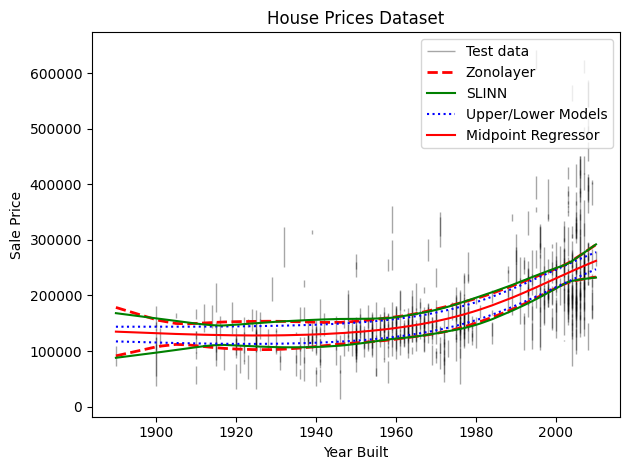

In [4]:
x_train = np.asarray(X_train).squeeze()
x_test = np.asarray(X_test).squeeze()

y_train_plot = np.asarray(y_train).squeeze()
y_test_plot = np.asarray(y_test).squeeze()

y_lower_train_plot = np.asarray(y_lower_train).squeeze()
y_upper_train_plot = np.asarray(y_upper_train).squeeze()

y_lower_test_plot = np.asarray(y_lower_test).squeeze()
y_upper_test_plot = np.asarray(y_upper_test).squeeze()

pred_train = np.asarray(pred_train).squeeze()
pred_test = np.asarray(pred_test).squeeze()

yl_zl = np.asarray(yl_zl).squeeze()
yu_zl = np.asarray(yu_zl).squeeze()
midpoint_model = np.asarray(midpoint_model).squeeze()


x_train = x_train * X_std + X_mean
x_test = x_test * X_std + X_mean


y_train_plot = y_train_plot * y_std + y_mean
y_test_plot = y_test_plot * y_std + y_mean

y_lower_train_plot = (
    y_lower_train_plot * y_std + y_mean
)

y_upper_train_plot = (
    y_upper_train_plot * y_std + y_mean
)

y_lower_test_plot = (
    y_lower_test_plot * y_std + y_mean
)

y_upper_test_plot = (
    y_upper_test_plot * y_std + y_mean
)

pred_train = pred_train * y_std + y_mean
pred_test = pred_test * y_std + y_mean

yl_zl = yl_zl * y_std + y_mean
yu_zl = yu_zl * y_std + y_mean
midpoint_model = midpoint_model * y_std + y_mean



train_idx = np.argsort(x_train)
test_idx = np.argsort(x_test)

upper_test = np.asarray(upper_test).squeeze()
lower_test = np.asarray(lower_test).squeeze()

upper_test = upper_test * y_std + y_mean
lower_test = lower_test * y_std + y_mean

upper_test_sorted = upper_test[test_idx]
lower_test_sorted = lower_test[test_idx]

x_train_sorted = x_train[train_idx]
x_test_sorted = x_test[test_idx]

y_train_sorted = y_train_plot[train_idx]
y_test_sorted = y_test_plot[test_idx]

y_lower_train_sorted = y_lower_train_plot[train_idx]
y_upper_train_sorted = y_upper_train_plot[train_idx]

y_lower_test_sorted = y_lower_test_plot[test_idx]
y_upper_test_sorted = y_upper_test_plot[test_idx]

pred_train_sorted = pred_train[train_idx]
pred_test_sorted = pred_test[test_idx]

yl_zl_sorted = yl_zl[test_idx]
yu_zl_sorted = yu_zl[test_idx]

midpoint_model_sorted = midpoint_model[test_idx]

slinn_lo_sorted = slinn_lo[test_idx]
slinn_hi_sorted = slinn_hi[test_idx]
slinn_mid_sorted = slinn_mid[test_idx]



plt.figure()


plt.vlines(
    x_test_sorted,
    y_lower_test_sorted,
    y_upper_test_sorted,
    color='black',
    alpha=0.35,
    linewidth=1.0,
    label='Test data'
)

plt.plot(
    x_test_sorted,
    yl_zl_sorted,
    'r--',
    linewidth=2,
    label='Zonolayer'
)

plt.plot(
    x_test_sorted,
    yu_zl_sorted,
    'r--',
    linewidth=2
)

plt.plot(
    x_test_sorted,
    slinn_lo_sorted,
    color='green',
    linestyle='-',
    linewidth=1.5,
    label='SLINN'
)

plt.plot(
    x_test_sorted,
    lower_test_sorted,
    'b:',
    linewidth=1.5,
    label='Upper/Lower Models'
)

plt.plot(
    x_test_sorted,
    upper_test_sorted,
    'b:',
    linewidth=1.5
)

# SLINN upper bound
plt.plot(
    x_test_sorted,
    slinn_hi_sorted,
    color='green',
    linestyle='-',
    linewidth=1.5
)

plt.plot(
    x_test_sorted,
    midpoint_model_sorted,
    'r-',
    linewidth=1.5,
    label='Midpoint Regressor'
)


plt.xlabel('Year Built')
plt.ylabel('Sale Price')

plt.legend()
plt.title("House Prices Dataset")
plt.tight_layout()

plt.savefig(
    "PDF/HousePricesNN.pdf",
    bbox_inches="tight"
)
plt.show()
